##### **1. Data Health & Feature Type Audit**

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats


# Plot styling
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Load raw training data
df = pd.read_csv("../data/raw/train.csv")

print(f"Dataset Shape: {df.shape}")
print(f"Duplicate Rows: {df.duplicated().sum()}")
print(f"Duplicate IDs: {df['Id'].duplicated().sum()}")

# Numerical vs Categorical split
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = df.select_dtypes(exclude=[np.number]).columns.tolist()

print(f"\nNumerical Columns ({len(num_cols)}): {num_cols[:10]}...")
print(f"Categorical Columns ({len(cat_cols)}): {cat_cols[:10]}...")


Dataset Shape: (1460, 81)
Duplicate Rows: 0
Duplicate IDs: 0

Numerical Columns (38): ['Id', 'MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1']...
Categorical Columns (43): ['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1']...


- **Observation:** Dhyan se dekho ki `MSSubClass` (Building Class) numerical list mein aayega, jabki woh asal mein ek categorical code hai `(20 = 1-Story, 60 = 2-Story)`. Ise hum Step 4 mein string mein convert karenge.

##### **2. Target Variable (SalePrice) Distribution & Skewness**

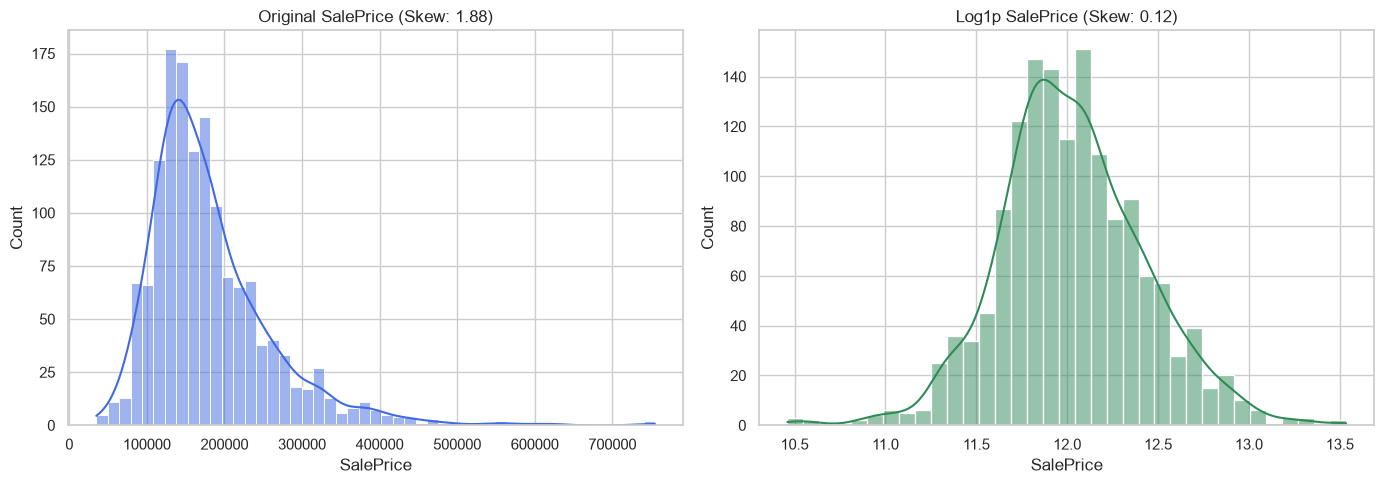

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Original SalePrice
sns.histplot(df["SalePrice"], kde=True, ax=axes[0], color="royalblue")
axes[0].set_title(f"Original SalePrice (Skew: {df['SalePrice'].skew():.2f})")

# Log-transformed SalePrice
log_price = np.log1p(df["SalePrice"])
sns.histplot(log_price, kde=True, ax=axes[1], color="seagreen")
axes[1].set_title(f"Log1p SalePrice (Skew: {log_price.skew():.2f})")

plt.tight_layout()
plt.show()


- **Decision Taken:** Original `SalePrice` strongly right-skewed (~1.88) hai. `np.log1p(SalePrice)` lagane se skewness ~0.12 ho jati hai (almost normal distribution), jo hamare RMSLE evaluation metric ke saath bhi perfectly align karta hai.

##### **3. Missing Values Diagnosis (Domain vs True Missing)**

Columns with Missing Values:

              Missing_Count  Missing_Pct
PoolQC                 1453    99.520548
MiscFeature            1406    96.301370
Alley                  1369    93.767123
Fence                  1179    80.753425
MasVnrType              872    59.726027
FireplaceQu             690    47.260274
LotFrontage             259    17.739726
GarageType               81     5.547945
GarageYrBlt              81     5.547945
GarageFinish             81     5.547945
GarageQual               81     5.547945
GarageCond               81     5.547945
BsmtExposure             38     2.602740
BsmtFinType2             38     2.602740
BsmtQual                 37     2.534247
BsmtCond                 37     2.534247
BsmtFinType1             37     2.534247
MasVnrArea                8     0.547945
Electrical                1     0.068493


C:\Users\navee\AppData\Local\Temp\ipykernel_3984\3065415808.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=missing_df.index[:15], y=missing_df["Missing_Pct"][:15], palette="viridis")


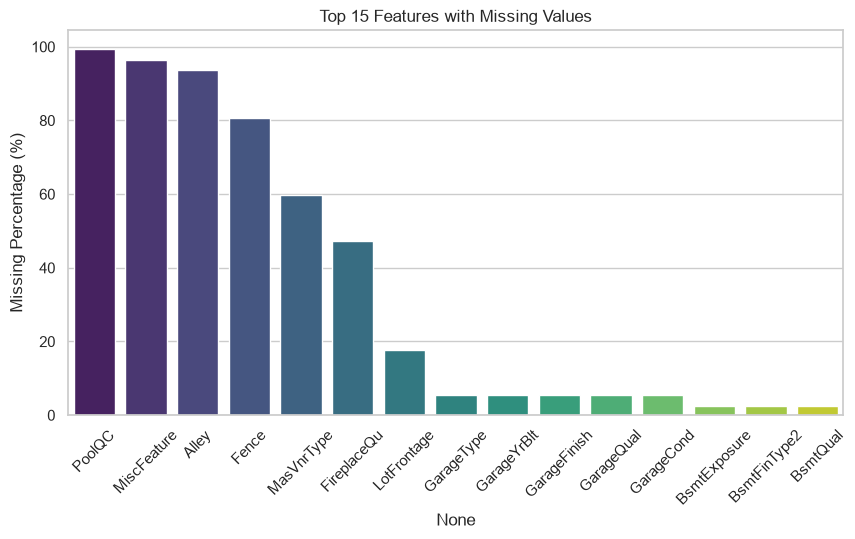

In [7]:
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
missing_pct = (missing / len(df)) * 100

missing_df = pd.DataFrame({"Missing_Count": missing, "Missing_Pct": missing_pct})
print("Columns with Missing Values:\n")
print(missing_df)

# Visualize Top 15 Missing Columns
plt.figure(figsize=(10, 5))
sns.barplot(x=missing_df.index[:15], y=missing_df["Missing_Pct"][:15], palette="viridis")
plt.xticks(rotation=45)
plt.ylabel("Missing Percentage (%)")
plt.title("Top 15 Features with Missing Values")
plt.show()


- **Insight:** `PoolQC (99.5%)`, `MiscFeature (96.3%)`, `Alley (93.7%)`, aur `Fence (80.7%)` mein NaN ka matlab missing data nahi hai—Kaggle data dictionary ke mutabik iska matlab "Feature Absent" (e.g., ghar mein pool nahi hai) hai. Sirf `LotFrontage (~17.7%)` aur `Electrical (1 row)` mein asli missing values hain.

##### **4. Correlation & Extreme Outlier Detection**

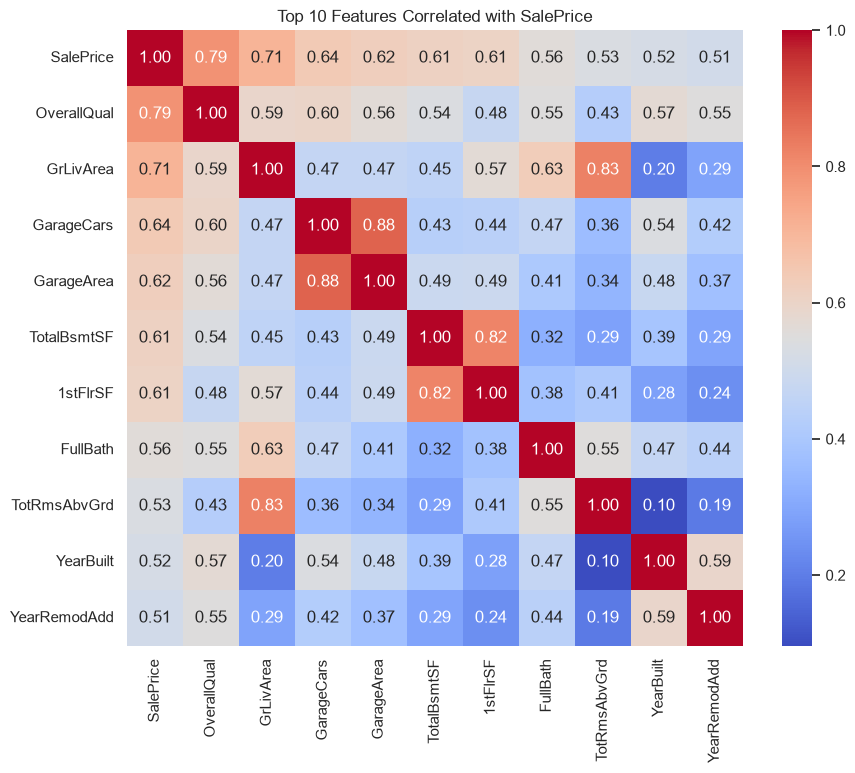

In [10]:
# Top 10 features correlated with SalePrice
corr_matrix = df[num_cols].corr()
top_corr_cols = corr_matrix["SalePrice"].abs().sort_values(ascending=False).head(11).index

plt.figure(figsize=(10, 8))
sns.heatmap(df[top_corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", square=True)
plt.title("Top 10 Features Correlated with SalePrice")
plt.show()


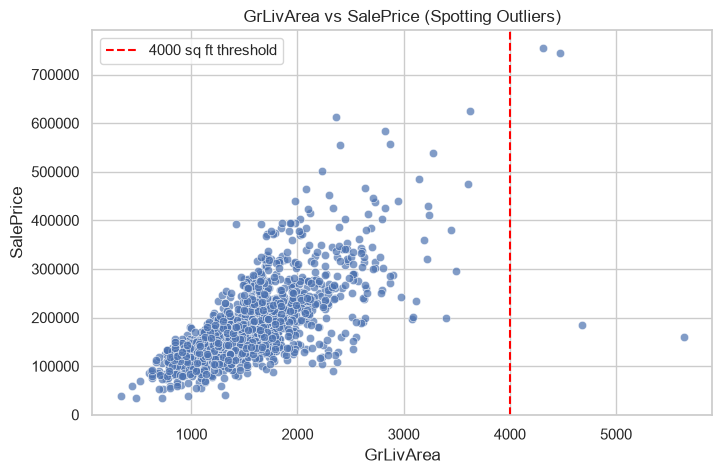


Extreme Outliers Detected:
        Id  GrLivArea  OverallQual  SalePrice SaleCondition
523    524       4676           10     184750       Partial
1298  1299       5642           10     160000       Partial


In [14]:
# Scatter plot to detect extreme outliers in GrLivArea (Above Grade Living Area)
plt.figure(figsize=(8, 5))
sns.scatterplot(x=df["GrLivArea"], y=df["SalePrice"], alpha=0.7)
plt.axvline(4000, color="red", linestyle="--", label="4000 sq ft threshold")
plt.title("GrLivArea vs SalePrice (Spotting Outliers)")
plt.legend()
plt.show()

# Print those specific outlier rows
outliers = df[(df["GrLivArea"] > 4000) & (df["SalePrice"] < 300000)]
print("\nExtreme Outliers Detected:")
print(outliers[["Id", "GrLivArea", "OverallQual", "SalePrice", "SaleCondition"]])


- **Decision Taken:** Scatter plot mein right side par 2 aise ghar dikhenge jinka area > 4000 sq ft hai, lekin price < $200,000 hai (partial sale outliers). Yeh regression line ko kharab kar sakte hain, isliye hum inhe Step 4 mein remove karenge.